In [ ]:
import os
# Force Colab to use Keras 2 to maintain compatibility with tensorflow_hub
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf
print(tf.__version__)

2.20.0


#MedSectAI - Enhancing Medical Research Paper Readability with NLP


The goal of this project is to create an NLP model that automatically divides
medical research papers into sections for better readability and understanding.
We'll explore multiple approaches ranging from baseline models to advanced
deep learning architectures, concluding with a multimodal model combining token,
character, and positional embeddings.

Reference Paper: https://arxiv.org/abs/1710.06071
Dataset Source: https://github.com/Franck-Dernoncourt/pubmed-rct


#Get Dataset


In [ ]:
!git clone https://github.com/Franck-Dernoncourt/pubmed-rct
!ls pubmed-rct

Cloning into 'pubmed-rct'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 39 (delta 8), reused 5 (delta 5), pack-reused 25 (from 1)
Receiving objects: 100% (39/39), 177.08 MiB | 39.81 MiB/s, done.
Resolving deltas: 100% (15/15), done.
PubMed_200k_RCT
PubMed_200k_RCT_numbers_replaced_with_at_sign
PubMed_20k_RCT
PubMed_20k_RCT_numbers_replaced_with_at_sign
README.md


#Analysing Dataset

In [ ]:
#check files in PubMed_20k_RCT and PubMed_20k_RCT_numbers_replaced_with_at_sign
!ls pubmed-rct/PubMed_20k_RCT/
!ls pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/


dev.txt  test.txt  train.txt
dev.txt  test.txt  train.txt


In [ ]:
#assigning directory
data_dir="/content/pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign"

In [ ]:
#check files in target directory
import os
for filename in os.listdir(data_dir):
  print([data_dir+filename])

['/content/pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_signtrain.txt']
['/content/pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_signdev.txt']
['/content/pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_signtest.txt']


#preprocessing Data

In [ ]:
#creating a function to read the lines of the doc
def get_lines(filename):
  """
  read the lines of the doc
  ARGS:
  filename: a string containing the path to the file
  RETURN:
  a list of strings with one string per line from target file path
  """
  with open(filename,'r') as f:
    lines=f.readlines()
  return lines

In [ ]:
#reading training file lines
train_lines=get_lines(data_dir+'/train.txt')
train_lines[:25]

['###24293578\n',
 'OBJECTIVE\tTo investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .\n',
 'METHODS\tA total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .\n',
 'METHODS\tOutcome measures included pain reduction and improvement in function scores and systemic inflammation markers .\n',
 'METHODS\tPain was assessed using the visual analog pain scale ( @-@ mm ) .\n',
 'METHODS\tSecondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , patient global assessment ( PGA ) of the severity of knee OA , and @-min walk distance ( @MWD ) .\n',
 'METHODS\tSerum levels of interleukin @ ( IL-@ ) , IL-@ , tumor necrosis factor ( TNF ) - , and 

In [ ]:
#converting it to data frame
import pandas as pd
train_df=pd.DataFrame(train_lines)
train_df[:10]

,0
0,###24293578\n
1,OBJECTIVE\tTo investigate the efficacy of @ we...
2,METHODS\tA total of @ patients with primary kn...
3,METHODS\tOutcome measures included pain reduct...
4,METHODS\tPain was assessed using the visual an...
5,METHODS\tSecondary outcome measures included t...
6,METHODS\tSerum levels of interleukin @ ( IL-@ ...
7,RESULTS\tThere was a clinically relevant reduc...
8,RESULTS\tThe mean difference between treatment...
9,"RESULTS\tFurther , there was a clinically rele..."


Converting data into format that best represents our mdoel.
how I am going to proceed
```
[{"line_number":0,
"target:"BACKGROUND",
"text":'emotional..........obesity.\n'
"total_lines":19},
```

In [ ]:
input_lines=get_lines(data_dir+'/train.txt')
input_lines[:27]


['###24293578\n',
 'OBJECTIVE\tTo investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .\n',
 'METHODS\tA total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .\n',
 'METHODS\tOutcome measures included pain reduction and improvement in function scores and systemic inflammation markers .\n',
 'METHODS\tPain was assessed using the visual analog pain scale ( @-@ mm ) .\n',
 'METHODS\tSecondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , patient global assessment ( PGA ) of the severity of knee OA , and @-min walk distance ( @MWD ) .\n',
 'METHODS\tSerum levels of interleukin @ ( IL-@ ) , IL-@ , tumor necrosis factor ( TNF ) - , and 

In [ ]:
#creating function to convert dataset into this list of dictionary
def preprocess_data_list(filename):
  """
  returns a list of dictionary that converts file into proper format
  """
  input_lines=get_lines(filename)#getting each line from file
  abstract_lines=""#create an empty abstract
  abstract_samples=[]#create an empty list of abstracts

  for line in input_lines:
    if line.startswith("###"):#ID line check
      abstract_id=line
      abstract_lines=""#resetting abstract string if it the line is an id line
    elif line.isspace():#new line check
      abstract_line_split=abstract_lines.splitlines()#split abstracts into separate lines

      #iterating through each line
      for abstract_line_number,abstract_line in enumerate(abstract_line_split):
        line_data={}#initialising empty string
        target_text_split=abstract_line.split("\t")#split target and text
        line_data["target"]=target_text_split[0]#assign target
        line_data["text"]=" ".join(target_text_split[1:])#assign text
        line_data["line_number"]=abstract_line_number
        line_data["total_lines"]=len(abstract_line_split)-1
        abstract_samples.append(line_data)#append to list


    else:#if above conditions aren't fullfilled
      abstract_lines+=line#add line to abstract


  return abstract_samples







In [ ]:
#get samples
train_samples=preprocess_data_list(data_dir+'/train.txt')
val_samples=preprocess_data_list(data_dir+'/dev.txt')
test_samples=preprocess_data_list(data_dir+'/test.txt')



In [ ]:
train_samples[:10]

[{'target': 'OBJECTIVE',
  'text': 'To investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .',
  'line_number': 0,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'A total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .',
  'line_number': 1,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'Outcome measures included pain reduction and improvement in function scores and systemic inflammation markers .',
  'line_number': 2,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'Pain was assessed using the visual analog pain scale ( @-@ mm ) .',
  'line_number': 3,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'Secondary outcome measures included the Western Ontari

In [ ]:
#creating required dataframes

train_df=pd.DataFrame(train_samples)
val_df=pd.DataFrame(val_samples)
test_df=pd.DataFrame(test_samples)
train_df.head()

,target,text,line_number,total_lines
0,OBJECTIVE,To investigate the efficacy of @ weeks of dail...,0,11
1,METHODS,A total of @ patients with primary knee OA wer...,1,11
2,METHODS,Outcome measures included pain reduction and i...,2,11
3,METHODS,Pain was assessed using the visual analog pain...,3,11
4,METHODS,Secondary outcome measures included the Wester...,4,11


In [ ]:
#distribution of targets
train_df['target'].value_counts()

,count
target,
METHODS,59353
RESULTS,57953
CONCLUSIONS,27168
BACKGROUND,21727
OBJECTIVE,13839


<Axes: ylabel='Frequency'>

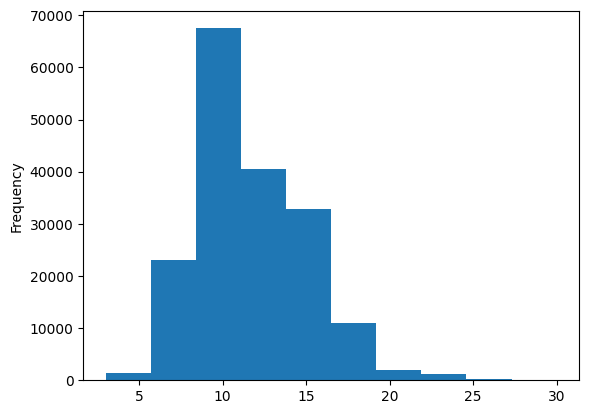

In [ ]:
#length of diffrent lines
train_df['total_lines'].plot.hist()

#get lists of sentences

In [ ]:
#convert the abstract text lines into lists
train_lines=train_df['text'].to_list()
val_lines=val_df['text'].to_list()
test_lines=test_df['text'].to_list()

In [ ]:
train_lines[:2]

['To investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .',
 'A total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .']

In [ ]:
#transformings targets into labels
#one hot labels
from sklearn.preprocessing import OneHotEncoder
OHE=OneHotEncoder()
train_labels_OHE=OHE.fit_transform(train_df[['target']])
val_labels_OHE=OHE.transform(val_df[['target']])
test_labels_OHE=OHE.transform(test_df[['target']])

In [ ]:
train_labels_OHE

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 180040 stored elements and shape (180040, 5)>

In [ ]:
import tensorflow as tf
train_labels_OHE=tf.constant(train_labels_OHE.toarray(), dtype=tf.float32)
val_labels_OHE=tf.constant(val_labels_OHE.toarray(), dtype=tf.float32)
test_labels_OHE=tf.constant(test_labels_OHE.toarray(), dtype=tf.float32)

In [ ]:
train_labels_OHE

<tf.Tensor: shape=(180040, 5), dtype=float32, numpy=
array([[0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]], dtype=float32)>

In [ ]:
#label encoding
from sklearn.preprocessing import LabelEncoder
LE=LabelEncoder()
train_labels=LE.fit_transform(train_df['target'])
val_labels=LE.transform(val_df['target'])
test_labels=LE.transform(test_df['target'])

train_labels

array([3, 2, 2, ..., 4, 1, 1])

In [ ]:
#get class names and number of classes from label encoder
num_classes=len(LE.classes_)
class_names=LE.classes_
print(class_names)
print(num_classes)

['BACKGROUND' 'CONCLUSIONS' 'METHODS' 'OBJECTIVE' 'RESULTS']
5


##baseline Model 0 Naive base tf idf vectorizer

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

#create a pipeline
model_0=Pipeline([
    ("tfidf",TfidfVectorizer()),
    ("clf",MultinomialNB())
])

#fit the pipeline
model_0.fit(train_lines,train_labels)

Pipeline(steps=[('tfidf', TfidfVectorizer()), ('clf', MultinomialNB())])

In [ ]:
#evaluation
baseline_score=model_0.score(val_lines,val_labels)
print(f"Our baseline model achieves an accuracy of: {baseline_score*100:.2f}%")

Our baseline model achieves an accuracy of: 72.18%


In [ ]:
#make preditions use baseline
baseline_preds=model_0.predict(val_lines)
baseline_preds[:20]

array([4, 1, 3, 2, 2, 2, 2, 2, 4, 4, 0, 4, 1, 1, 2, 2, 4, 1, 4, 4])

###importing helper functions

In [ ]:
#importing helper funtions from github
!wget https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/helper_functions.py
from helper_functions import unzip_data,create_tensorboard_callback,plot_loss_curves,calculate_results

--2026-06-01 13:01:19--  https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/helper_functions.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10246 (10K) [text/plain]
Saving to: ‘helper_functions.py’

helper_functions.py 100%[===================>]  10.01K  --.-KB/s    in 0s      

2026-06-01 13:01:19 (116 MB/s) - ‘helper_functions.py’ saved [10246/10246]



In [ ]:
#calculate baseline results
baseline_results=calculate_results(y_true=val_labels,
                                   y_pred=baseline_preds)
baseline_results

{'accuracy': 72.1832384482987,
 'precision': 0.7186466952323352,
 'recall': 0.7218323844829869,
 'f1': 0.6989250353450294}

In [ ]:
#preparing  our data for sequence models
#finding average length of senences

sent_lens=[len(sentence.split()) for sentence in train_lines]

In [ ]:
avg_sen_length=sum(sent_lens)/len(sent_lens)
avg_sen_length

26.338269273494777

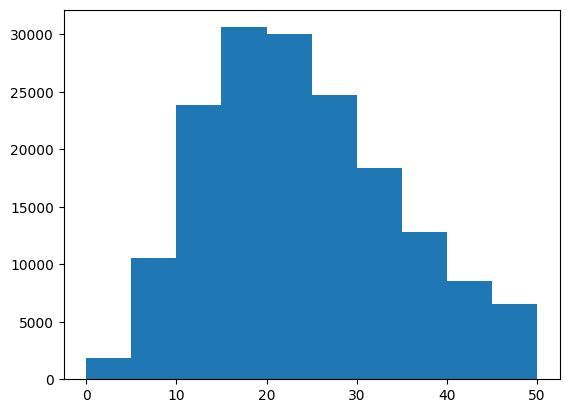

In [ ]:
#visualizing sent_lens
import matplotlib.pyplot as plt
plt.hist(sent_lens,bins=10,range=[0,50]);

In [ ]:
#how long of sentences length contains 95percent of examples
import numpy as np

out_seq_length=np.percentile(sent_lens,95)
out_seq_length

np.float64(55.0)

In [ ]:
#max seq length
max_seq_length=max(sent_lens)
max_seq_length

296

In [ ]:
#finding total number of unique words in our vocab
from collections import Counter
word_counts=Counter()
for sent in train_lines:
  word_counts.update(sent.lower().split())


max_tokens=len(word_counts)

In [ ]:
max_tokens

69732

In [ ]:
#create text vectorizer layer
from tensorflow.keras.layers import TextVectorization
text_vectorizer=TextVectorization(max_tokens=max_tokens,
                                  output_sequence_length=int(out_seq_length),
                                  pad_to_max_tokens=True)



In [ ]:
#adapting text vec to training sentences
text_vectorizer.adapt(train_lines)


In [ ]:
#test out text vectorizer on random sentences
import random
target_line=random.choice(train_lines)
print(f"Text:\n{target_line}")
print(f"\nLength of text:{len(target_line)}")
print(f"\nVector:{text_vectorizer([target_line])}")

Text:
A low level of myocardial CoQ@ is related to the severity of HF .

Length of text:65

Vector:[[   8  220  204    4  477 5765   20  328    6    2  332    4  783    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0]]


In [ ]:
text_vectorizer.get_config()

{'name': 'text_vectorization_1',
 'trainable': True,
 'dtype': 'string',
 'batch_input_shape': (None,),
 'max_tokens': 69732,
 'standardize': 'lower_and_strip_punctuation',
 'split': 'whitespace',
 'ngrams': None,
 'output_mode': 'int',
 'output_sequence_length': 55,
 'pad_to_max_tokens': True,
 'sparse': False,
 'ragged': False,
 'vocabulary': None,
 'idf_weights': None,
 'encoding': 'utf-8',
 'vocabulary_size': 64841}

In [ ]:
#create token embedding layer
from tensorflow.keras import layers
embedding=layers.Embedding(input_dim=max_tokens,
                           output_dim=128,
                           input_length=int(out_seq_length),
                           mask_zero=True)

In [ ]:
#turning datasets into datasets
train_dataset=tf.data.Dataset.from_tensor_slices((train_lines,train_labels_OHE))
val_dataset=tf.data.Dataset.from_tensor_slices((val_lines,val_labels_OHE))
test_dataset=tf.data.Dataset.from_tensor_slices((test_lines,test_labels_OHE))

In [ ]:
#creating batches
train_dataset=train_dataset.batch(32).prefetch(1)
val_dataset=val_dataset.batch(32).prefetch(1)
test_dataset=test_dataset.batch(32).prefetch(1)

In [ ]:
#Conv1D with tokens embeddings
from tensorflow.keras import layers
inputs=layers.Input(shape=(1,),dtype=tf.string)
x=text_vectorizer(inputs)
x=embedding(x)
x=layers.Conv1D(filters=64,kernel_size=5,activation="relu")(x)
x=layers.GlobalAveragePooling1D()(x)
outputs=layers.Dense(num_classes,activation="softmax")(x)
model_1=tf.keras.Model(inputs,outputs,name="model_1_Conv1D")
model_1.summary()


Model: "model_1_Conv1D"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_7 (InputLayer)        [(None, 1)]               0         
                                                                 
 text_vectorization_1 (Text  (None, 55)                0         
 Vectorization)                                                  
                                                                 
 embedding_1 (Embedding)     (None, 55, 128)           8925696   
                                                                 
 conv1d_6 (Conv1D)           (None, 51, 64)            41024     
                                                                 
 global_average_pooling1d_5  (None, 64)                0         
  (GlobalAveragePooling1D)                                       
                                                                 
 dense_19 (Dense)            (None, 5)              

In [ ]:
#compile the model
model_1.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])


In [ ]:
#creating callbacks
from helper_functions import create_tensorboard_callback
SAVE_DIR="model_logs"
tensorboard_callback=create_tensorboard_callback(dir_name=SAVE_DIR,
                                                 experiment_name="Conv1D")

from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint=ModelCheckpoint(filepath='bestmodel.keras',
                           monitor='accuracy',
                           mode='max',
                           save_best_only=True)



Saving TensorBoard log files to: model_logs/Conv1D/20260601-152417


In [ ]:
#fit the model
history_1=model_1.fit(train_dataset,
                      steps_per_epoch=int(0.1*len(train_dataset)),
                      epochs=20,
                      validation_data=val_dataset,
                      callbacks=[tensorboard_callback,checkpoint])

Epoch 1/20
562/562 [==============================] - 27s 46ms/step - loss: 0.9421 - accuracy: 0.6274 - val_loss: 0.7210 - val_accuracy: 0.7263
Epoch 2/20
562/562 [==============================] - 10s 18ms/step - loss: 0.6844 - accuracy: 0.7456 - val_loss: 0.6621 - val_accuracy: 0.7630
Epoch 3/20
562/562 [==============================] - 8s 14ms/step - loss: 0.6387 - accuracy: 0.7648 - val_loss: 0.6179 - val_accuracy: 0.7782
Epoch 4/20
562/562 [==============================] - 9s 16ms/step - loss: 0.6068 - accuracy: 0.7811 - val_loss: 0.5942 - val_accuracy: 0.7815
Epoch 5/20
562/562 [==============================] - 9s 16ms/step - loss: 0.6024 - accuracy: 0.7877 - val_loss: 0.5730 - val_accuracy: 0.7968
Epoch 6/20
562/562 [==============================] - 7s 13ms/step - loss: 0.5924 - accuracy: 0.7857 - val_loss: 0.5636 - val_accuracy: 0.7995
Epoch 7/20
562/562 [==============================] - 13s 23ms/step - loss: 0.5683 - accuracy: 0.7957 - val_loss: 0.5531 - val_accuracy: 0.8

562/562 [==============================] - 3s 5ms/step - loss: 0.6533 - accuracy: 0.7750 - val_loss: 0.5367 - val_accuracy: 0.8072


In [ ]:
model_1.evaluate(test_dataset)

942/942 [==============================] - 3s 4ms/step - loss: 0.5510 - accuracy: 0.8012


[0.5509992837905884, 0.8012278079986572]

In [ ]:
#making predictions
model_1_preds=model_1.predict(test_dataset)
model_1_preds[:10],model_1_preds.shape

942/942 [==============================] - 2s 2ms/step


(array([[1.9774203e-01, 3.7658330e-02, 5.3183419e-01, 1.3490734e-01,
         9.7858123e-02],
        [7.9491911e-03, 6.3289348e-03, 8.0910844e-01, 1.0646763e-02,
         1.6596666e-01],
        [5.4571708e-04, 2.5061674e-03, 7.7826738e-01, 3.9695288e-04,
         2.1828377e-01],
        [2.3598128e-04, 1.6483603e-04, 5.6515980e-01, 7.0871296e-04,
         4.3373075e-01],
        [4.2534055e-04, 2.5655441e-02, 2.3434202e-03, 1.7954316e-04,
         9.7139627e-01],
        [2.4620451e-08, 2.7200493e-05, 1.5910909e-07, 1.7050251e-08,
         9.9997258e-01],
        [4.6755267e-07, 6.1179184e-05, 1.0919647e-04, 4.5238602e-07,
         9.9982870e-01],
        [7.5852776e-01, 8.6707383e-02, 3.1648378e-03, 1.4926974e-01,
         2.3301803e-03],
        [3.9887702e-01, 4.5227513e-01, 9.0907980e-03, 9.3165711e-02,
         4.6591297e-02],
        [4.6049672e-01, 2.5807080e-01, 8.1613660e-03, 2.7108705e-01,
         2.1840867e-03]], dtype=float32),
 (30135, 5))

In [ ]:
#convert into pred probs
model_1_pred_probs=tf.squeeze(tf.round(model_1_preds))
model_1_pred_probs=(model_1_pred_probs)
model_1_pred=tf.argmax(model_1_preds,axis=1).numpy()
model_1_pred[:10]

array([2, 2, 2, 2, 4, 4, 4, 0, 1, 0])

In [ ]:
#calculate model_1 results
model_1_results=calculate_results(y_true=test_labels,

                                  y_pred=model_1_pred)
model_1_results,baseline_results

({'accuracy': 80.12278081964493,
  'precision': 0.797772771069436,
  'recall': 0.8012278081964493,
  'f1': 0.7976624775285636},
 {'accuracy': 72.1832384482987,
  'precision': 0.7186466952323352,
  'recall': 0.7218323844829869,
  'f1': 0.6989250353450294})

#Model2: Using Hugging Face pretained feature Extractor

In [ ]:
from sentence_transformers import SentenceTransformer
import numpy as np
import tensorflow as tf

# Download the  hugging face MiniLM model
print("Downloading MiniLM...")
hf_model = SentenceTransformer('all-MiniLM-L6-v2')

# Convert sentences to embeddings
print("Converting training sentences...")
train_embeds = hf_model.encode(train_lines, batch_size=32, show_progress_bar=True)
print("Converting validation sentences...")
val_embeds = hf_model.encode(val_lines, batch_size=32, show_progress_bar=True)

# Create the new fast datasets
train_dataset_hf = tf.data.Dataset.from_tensor_slices((train_embeds, train_labels_OHE)).batch(32).prefetch(tf.data.AUTOTUNE)
val_dataset_hf = tf.data.Dataset.from_tensor_slices((val_embeds, val_labels_OHE)).batch(32).prefetch(tf.data.AUTOTUNE)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Converting training sentences...


Batches:   0%|          | 0/5627 [00:00<?, ?it/s]

Converting validation sentences...


Batches:   0%|          | 0/945 [00:00<?, ?it/s]

In [ ]:
import random
# testing embeddings with MiniLM
random_train_sen = random.choice(train_lines)
print(f"Text:\n{random_train_sen}")

# Using the hf_model to encode the random sentence
random_sen_embd = hf_model.encode([random_train_sen])

print(f"\nsentence embedding shape: {random_sen_embd.shape}")
print(f"sentence embedding (first 20 values):\n{random_sen_embd[0][:20]}")
print(f"\nLength of embedding: {len(random_sen_embd[0])}")

Text:
Higher low-density lipoprotein cholesterol is associated with more rapid chronic kidney disease progression ; reduction in cholesterol with statins , in conjunction with statins ' pleiotropic effects , such as decreasing inflammation , may be renoprotective .

sentence embedding shape: (1, 384)
sentence embedding (first 20 values):
[-0.03442197 -0.04132985 -0.01909311  0.00626736  0.02183571 -0.00645202
 -0.04850325  0.08536621  0.02673637 -0.03156437 -0.0338094   0.10119805
  0.03321955 -0.00013324  0.02257752 -0.0370623  -0.00422824  0.05650144
 -0.12797748 -0.00262156]

Length of embedding: 384


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

# Build Model 2 using pre-computed MiniLM embeddings (384 dimensions)
model_2_input = layers.Input(shape=(384,), dtype=tf.float32, name="embedding_input")
x = layers.Dense(128, activation="relu")(model_2_input)
model_2_output = layers.Dense(num_classes, activation="softmax")(x)

model_2 = tf.keras.Model(inputs=model_2_input, outputs=model_2_output, name="model_2_minilm_feature_extractor")

# Compile the model
model_2.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])

model_2.summary()

Model: "model_2_minilm_feature_extractor"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_input (InputLaye  [(None, 384)]             0         
 r)                                                              
                                                                 
 dense_17 (Dense)            (None, 128)               49280     
                                                                 
 dense_18 (Dense)            (None, 5)                 645       
                                                                 
Total params: 49925 (195.02 KB)
Trainable params: 49925 (195.02 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
#compile model
model_2.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])
#summary
model_2.summary()

Model: "model_2_minilm_feature_extractor"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_input (InputLaye  [(None, 384)]             0         
 r)                                                              
                                                                 
 dense_17 (Dense)            (None, 128)               49280     
                                                                 
 dense_18 (Dense)            (None, 5)                 645       
                                                                 
Total params: 49925 (195.02 KB)
Trainable params: 49925 (195.02 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
# Train Model 2 using the Hugging Face embedding datasets
history_2 = model_2.fit(train_dataset_hf,
                        steps_per_epoch=int(0.1 * len(train_dataset_hf)),
                        epochs=10,
                        validation_data=val_dataset_hf,
                        validation_steps=int(0.1 * len(val_dataset_hf)),
                        callbacks=[tensorboard_callback])

Epoch 1/10
562/562 [==============================] - 3s 6ms/step - loss: 0.7303 - accuracy: 0.7213 - val_loss: 0.7102 - val_accuracy: 0.7201
Epoch 2/10
562/562 [==============================] - 2s 4ms/step - loss: 0.7106 - accuracy: 0.7283 - val_loss: 0.6987 - val_accuracy: 0.7281
Epoch 3/10
562/562 [==============================] - 3s 5ms/step - loss: 0.7056 - accuracy: 0.7274 - val_loss: 0.6921 - val_accuracy: 0.7367
Epoch 4/10
562/562 [==============================] - 2s 4ms/step - loss: 0.6875 - accuracy: 0.7398 - val_loss: 0.6952 - val_accuracy: 0.7294
Epoch 5/10
562/562 [==============================] - 2s 4ms/step - loss: 0.6966 - accuracy: 0.7365 - val_loss: 0.6889 - val_accuracy: 0.7347
Epoch 6/10
562/562 [==============================] - 2s 4ms/step - loss: 0.7046 - accuracy: 0.7313 - val_loss: 0.6739 - val_accuracy: 0.7443
Epoch 7/10
562/562 [==============================] - 2s 4ms/step - loss: 0.6858 - accuracy: 0.7402 - val_loss: 0.6721 - val_accuracy: 0.7470
Epoch 

In [ ]:
# 1. Create the test embeddings using the HF model
print("Converting test sentences to MiniLM embeddings...")
test_embeds = hf_model.encode(test_lines, batch_size=32, show_progress_bar=True)

# 2. Create the test dataset compatible with model_2_hf
test_dataset_hf = tf.data.Dataset.from_tensor_slices((test_embeds, test_labels_OHE)).batch(32).prefetch(tf.data.AUTOTUNE)

# 3. Evaluate the model using the correct dataset
model_2_hf.evaluate(test_dataset_hf)

Converting test sentences to MiniLM embeddings...


Batches:   0%|          | 0/942 [00:00<?, ?it/s]

942/942 [==============================] - 3s 4ms/step - loss: 0.6327 - accuracy: 0.7638


[0.6326919198036194, 0.7638294100761414]

In [ ]:
# model 2 hf prediction, pred probs and pred labels
model_2_preds = model_2_hf.predict(test_dataset_hf)
model_2_preds[:10], model_2_preds.shape

942/942 [==============================] - 1s 2ms/step


(array([[6.13343596e-01, 5.67180291e-02, 7.52360933e-03, 3.17652822e-01,
         4.76193521e-03],
        [7.96260387e-02, 7.98685383e-03, 7.06282079e-01, 1.00599505e-01,
         1.05505578e-01],
        [2.78509315e-03, 4.25901875e-04, 9.88512158e-01, 4.31621261e-03,
         3.96058662e-03],
        [1.65436640e-02, 1.58119982e-03, 8.35566938e-01, 2.50698868e-02,
         1.21238388e-01],
        [9.83171463e-02, 3.83471280e-01, 1.10926048e-03, 2.57542972e-02,
         4.91348028e-01],
        [1.17740454e-03, 9.93200578e-03, 6.74498081e-03, 2.47410557e-04,
         9.81898248e-01],
        [1.45469159e-02, 8.59959796e-02, 8.51083174e-02, 1.12628546e-02,
         8.03085864e-01],
        [8.30088675e-01, 5.75033277e-02, 1.01779297e-04, 1.10586800e-01,
         1.71938573e-03],
        [1.20288292e-02, 9.00377452e-01, 2.81750206e-02, 7.54056498e-03,
         5.18780388e-02],
        [5.32831073e-01, 1.21006772e-01, 1.28376603e-01, 1.99034765e-01,
         1.87507663e-02]], dtype=flo

In [ ]:
model_2_pred_probs = tf.squeeze(tf.round(model_2_preds))
model_2_pred_labels = tf.argmax(model_2_preds, axis=1).numpy()
model_2_pred_labels[:10]

array([0, 2, 2, 2, 4, 4, 4, 0, 1, 0])

In [ ]:
# result model_2 using MiniLM
model_2_results = calculate_results(y_true=test_labels,
                                  y_pred=model_2_pred_labels)
model_2_results

{'accuracy': 76.38294342127094,
 'precision': 0.7575912129918678,
 'recall': 0.7638294342127094,
 'f1': 0.7593761314656328}

#Model 3: Creating char-level tokenisation


In [ ]:
#make function to split sentences into chars
def split_chars(text):
  return " ".join(list(text))


#text splitting non-char-level seq into vchars
split_chars(random_train_sen)

"H i g h e r   l o w - d e n s i t y   l i p o p r o t e i n   c h o l e s t e r o l   i s   a s s o c i a t e d   w i t h   m o r e   r a p i d   c h r o n i c   k i d n e y   d i s e a s e   p r o g r e s s i o n   ;   r e d u c t i o n   i n   c h o l e s t e r o l   w i t h   s t a t i n s   ,   i n   c o n j u n c t i o n   w i t h   s t a t i n s   '   p l e i o t r o p i c   e f f e c t s   ,   s u c h   a s   d e c r e a s i n g   i n f l a m m a t i o n   ,   m a y   b e   r e n o p r o t e c t i v e   ."

In [ ]:
#split seq-level datasplits itno character level data splits
train_chars=[split_chars(line) for line in train_lines]
val_chars=[split_chars(line) for line in val_lines]
test_chars=[split_chars(line) for line in test_lines]

In [ ]:
from functools import total_ordering
#avg-char length
avg_char_length=np.mean([len(line) for line in train_lines])
avg_char_length

np.float64(149.3662574983337)

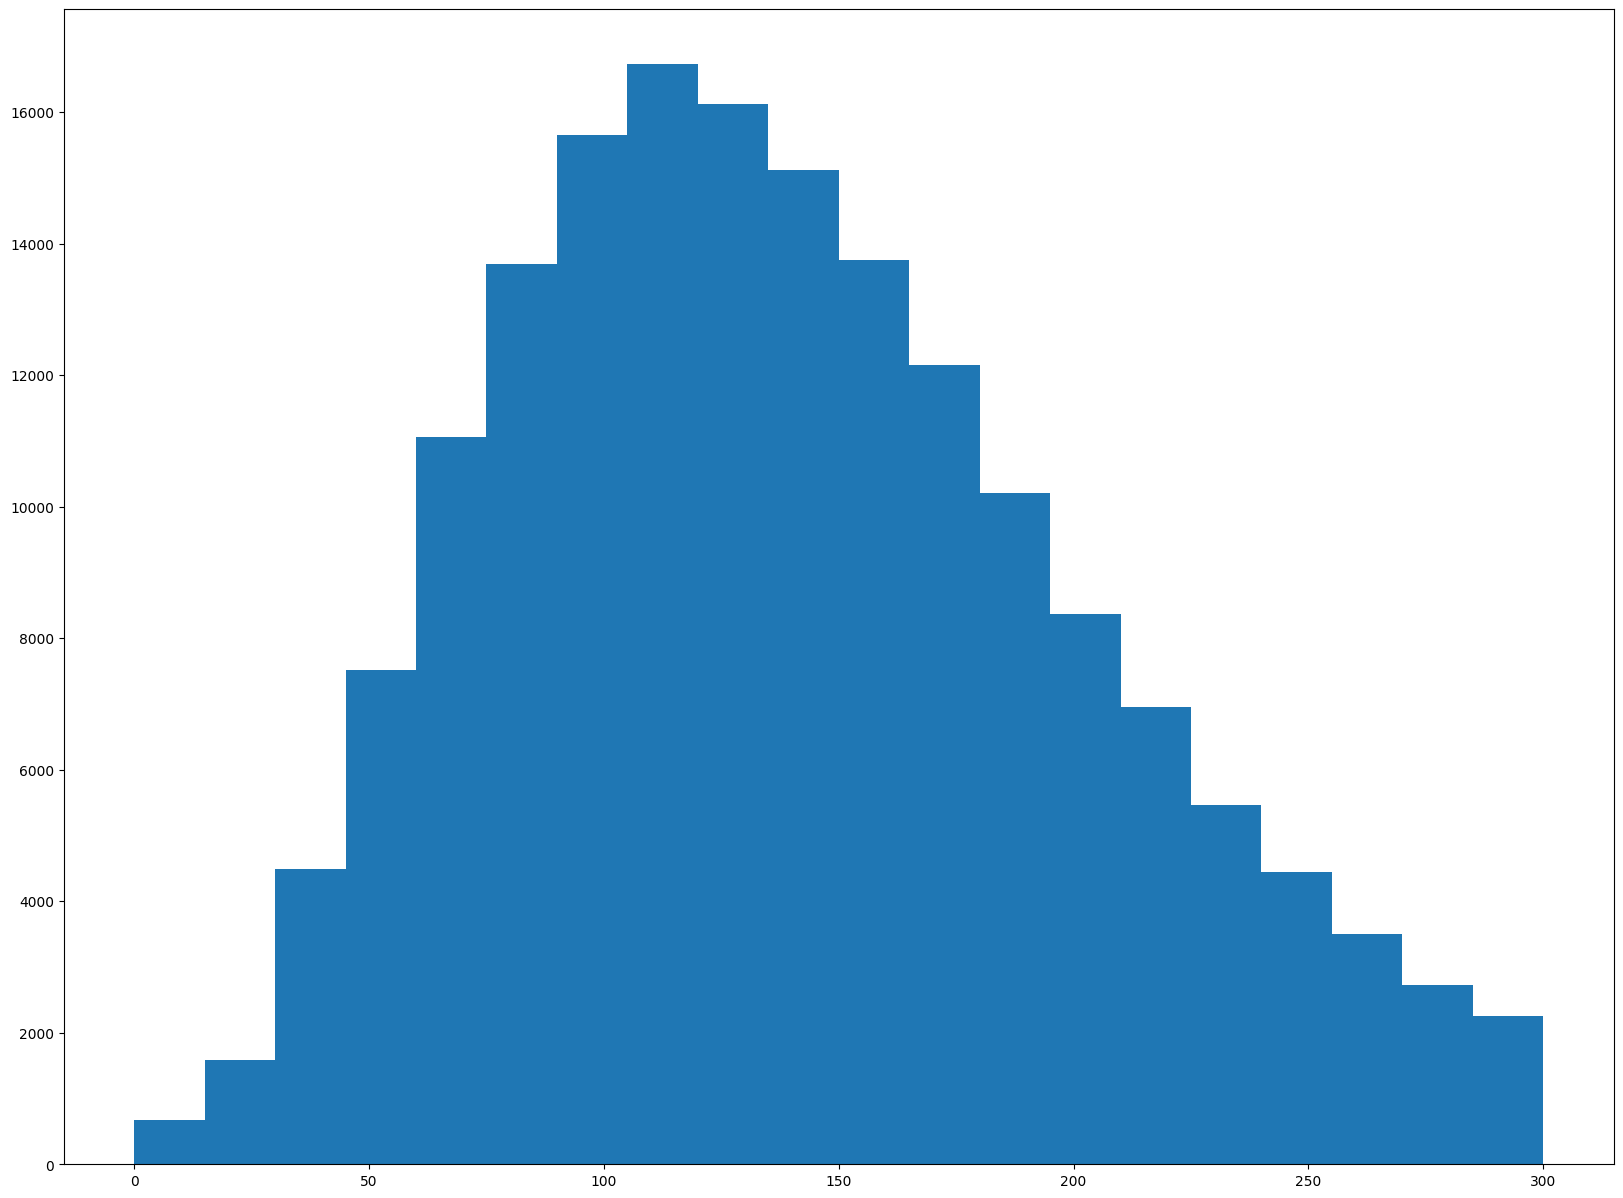

In [ ]:
#check the distribution of chars
import matplotlib.pyplot as plt
plt.figure(figsize=(20,15))
plt.hist([len(line) for line in train_lines],bins=20,range=[0,300]);

In [ ]:
#find what char length covers 95% seq
max_char_length=np.percentile([len(line) for line in train_lines],95)
max_char_length

np.float64(290.0)

In [ ]:
#get all keyboard chars
import string
chars=string.ascii_lowercase+string.digits+string.punctuation
chars

'abcdefghijklmnopqrstuvwxyz0123456789!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
#create char level tokenisation
num_char_tokens=len(chars)+2#for space and ['unk']
char_vectorizer=TextVectorization(max_tokens=num_char_tokens,
                                  output_sequence_length=int(max_char_length),
                                  name="char_vectorizer")



In [ ]:
#adapt it to train sentences
char_vectorizer.adapt(train_chars)

In [ ]:
#check character vocab stats
char_vocab=char_vectorizer.get_vocabulary()
print(f"number fo diff characters :{len(char_vocab)}")
print(f"first 10 characters in vocab:{char_vocab[:10]}")
print(f"last 10 characters in vocab:{char_vocab[-10:]}")


number fo diff characters :28
first 10 characters in vocab:['', '[UNK]', np.str_('e'), np.str_('t'), np.str_('i'), np.str_('a'), np.str_('n'), np.str_('o'), np.str_('r'), np.str_('s')]
last 10 characters in vocab:[np.str_('g'), np.str_('y'), np.str_('w'), np.str_('v'), np.str_('b'), np.str_('k'), np.str_('x'), np.str_('z'), np.str_('q'), np.str_('j')]


In [ ]:
#creating a character embedding
from tensorflow.keras import layers
char_embedding=layers.Embedding(input_dim=len(char_vocab),
                                output_dim=32,
                                mask_zero=True,
                                name="char_embedding")

In [ ]:
#test our embedding layer
import random
target_char=random.choice(train_chars)
print(f"Text:\n{target_char}")
print(f"\nLength of text:{len(target_char)}")
print(f"\nVector:{char_vectorizer([target_char])}")
print(f"\nEmbedding:{char_embedding(char_vectorizer([target_char]))}")


Text:
W e   a i m e d   t o   d e t e r m i n e   t h e   v a l u e   o f   N T - p r o B N P   i n   a d u l t s   w i t h   T o F   a n d   e s t a b l i s h   i t s   r e l a t i o n s h i p   w i t h   e c h o c a r d i o g r a p h y   a n d   e x e r c i s e   c a p a c i t y   .

Length of text:279

Vector:[[20  2  5  4 15  2 10  3  7 10  2  3  2  8 15  4  6  2  3 13  2 21  5 12
  16  2  7 17  6  3 14  8  7 22  6 14  4  6  5 10 16 12  3  9 20  4  3 13
   3  7 17  5  6 10  2  9  3  5 22 12  4  9 13  4  3  9  8  2 12  5  3  4
   7  6  9 13  4 14 20  4  3 13  2 11 13  7 11  5  8 10  4  7 18  8  5 14
  13 19  5  6 10  2 24  2  8 11  4  9  2 11  5 14  5 11  4  3 19  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0 

In [ ]:
#creating model
from tensorflow.keras import layers
inputs=layers.Input(shape=(1,),dtype=tf.string)
x=char_vectorizer(inputs)
x=char_embedding(x)
x=layers.Conv1D(64,
                kernel_size=5,
                padding="same",
                activation="relu")(x)
x=layers.Conv1D(64,
                kernel_size=5,
                padding="same",
                activation="relu")(x)
x=layers.GlobalAveragePooling1D()(x)
x=layers.Dense(128,activation="relu")(x)
outputs=layers.Dense(num_classes,activation="softmax")(x)

model_3=tf.keras.Model(inputs,outputs,name="model_3_char_level_conv")
model_3.summary()

Model: "model_3_char_level_conv"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_8 (InputLayer)        [(None, 1)]               0         
                                                                 
 char_vectorizer (TextVecto  (None, 290)               0         
 rization)                                                       
                                                                 
 char_embedding (Embedding)  (None, 290, 32)           896       
                                                                 
 conv1d_7 (Conv1D)           (None, 290, 64)           10304     
                                                                 
 conv1d_8 (Conv1D)           (None, 290, 64)           20544     
                                                                 
 global_average_pooling1d_6  (None, 64)                0         
  (GlobalAveragePooling1D)                 

In [ ]:
#compile model
model_3.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])


In [ ]:
#creating dataset and batching
train_dataset=tf.data.Dataset.from_tensor_slices((train_chars,train_labels_OHE))
val_dataset=tf.data.Dataset.from_tensor_slices((val_chars,val_labels_OHE))
test_dataset=tf.data.Dataset.from_tensor_slices((test_chars,test_labels_OHE))

#creating prefething and batching
train_dataset=train_dataset.batch(32).prefetch(1)
val_dataset=val_dataset.batch(32).prefetch(1)
test_dataset=test_dataset.batch(32).prefetch(1)

In [ ]:
#fittting
history_model_3=model_3.fit(train_dataset,
                          steps_per_epoch=int(0.1*len(train_dataset)),
                          epochs=10,
                          validation_data=val_dataset,
                          callbacks=[tensorboard_callback])

Epoch 1/10
562/562 [==============================] - 10s 13ms/step - loss: 1.4156 - accuracy: 0.3529 - val_loss: 1.3427 - val_accuracy: 0.3662
Epoch 2/10
562/562 [==============================] - 9s 16ms/step - loss: 1.3210 - accuracy: 0.3986 - val_loss: 1.2749 - val_accuracy: 0.4574
Epoch 3/10
562/562 [==============================] - 7s 12ms/step - loss: 1.2302 - accuracy: 0.4785 - val_loss: 1.1739 - val_accuracy: 0.5123
Epoch 4/10
562/562 [==============================] - 8s 14ms/step - loss: 1.1567 - accuracy: 0.5156 - val_loss: 1.1232 - val_accuracy: 0.5361
Epoch 5/10
562/562 [==============================] - 8s 14ms/step - loss: 1.0974 - accuracy: 0.5444 - val_loss: 1.0402 - val_accuracy: 0.5678
Epoch 6/10
562/562 [==============================] - 9s 15ms/step - loss: 1.0382 - accuracy: 0.5696 - val_loss: 0.9918 - val_accuracy: 0.5928
Epoch 7/10
562/562 [==============================] - 10s 17ms/step - loss: 1.0062 - accuracy: 0.5848 - val_loss: 0.9666 - val_accuracy: 0.60

In [ ]:
#calculating model_3results
model_3_pred=model_3.predict(test_dataset)


942/942 [==============================] - 4s 4ms/step


In [ ]:
#model_3_pred_probs and pred_lables
model_3_pred_probs=tf.squeeze(tf.round(model_3_pred))
model_3_pred_labels=tf.argmax(model_3_pred,axis=1).numpy()
model_3_pred_labels[:10]

array([2, 2, 2, 2, 4, 4, 4, 1, 4, 1])

In [ ]:
#results
model_3_results=calculate_results(y_true=test_labels,
                                  y_pred=model_3_pred_labels)
model_3_results

{'accuracy': 66.44433383109342,
 'precision': 0.678774812120801,
 'recall': 0.6644433383109342,
 'f1': 0.6667206487691607}

#Model 4: Multimodal(input) model
* character embedding+ toke embedding

In [ ]:
# combining custom token embd (Model 1) + char embd (Hybrid model)

# 1. Setup token inputs/model using layers from Model 1
token_inputs = layers.Input(shape=(1,), dtype=tf.string, name="token_input_layer")
token_vectors = text_vectorizer(token_inputs)
token_embeddings = embedding(token_vectors)
x_token = layers.Conv1D(64, kernel_size=5, padding="same", activation="relu")(token_embeddings)
x_token = layers.GlobalAveragePooling1D()(x_token)
token_outputs = layers.Dense(128, activation="relu", name="token_dense_layer")(x_token)
token_model = tf.keras.Model(token_inputs, token_outputs, name="token_model")

# 2. Setup char inputs/model
char_inputs = layers.Input(shape=(1,), dtype=tf.string, name="char_input_layer")
x_char = char_vectorizer(char_inputs)
x_char = char_embedding(x_char)
char_outputs = layers.Bidirectional(layers.LSTM(32), name="bidirectional_layer")(x_char)
char_model = tf.keras.Model(char_inputs, char_outputs, name="char_model")

# 3. Concatenate and add complexity with deeper Dense layers
combined = layers.Concatenate(name="token_char_hybrid")([token_model.output, char_model.output])

#stacking dense layers for better feature extraction
z = layers.Dense(256, activation="relu")(combined)
z = layers.Dropout(0.5)(z)
z = layers.Dense(128, activation="relu")(z)
z = layers.Dropout(0.3)(z)

outputs = layers.Dense(num_classes, activation="softmax", name="output_layer")(z)

model_4 = tf.keras.Model(inputs=[token_model.input, char_model.input],
                         outputs=outputs,
                         name="model_4_hybrid_custom_tokens")

model_4.summary()

Model: "model_4_hybrid_custom_tokens"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 token_input_layer (InputLa  [(None, 1)]                  0         []                            
 yer)                                                                                             
                                                                                                  
 text_vectorization_1 (Text  (None, 55)                   0         ['token_input_layer[0][0]']   
 Vectorization)                                                                                   
                                                                                                  
 embedding_1 (Embedding)     (None, 55, 128)              8925696   ['text_vectorization_1[1][0]']
                                                                       

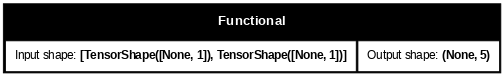

In [ ]:
#plot hybrid token and character model
import tensorflow as tf
from keras.utils import plot_model

plot_model(model_4,dpi=60,show_shapes=True)

In [ ]:
#compile token char model
model_4.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])

In [ ]:
#creating dataset and prefetched batches
train_dataset_data=tf.data.Dataset.from_tensor_slices((train_lines,train_chars))
val_dataset_data=tf.data.Dataset.from_tensor_slices((val_lines,val_chars))
test_dataset_data=tf.data.Dataset.from_tensor_slices((test_lines,test_chars))

train_dataset_labels=tf.data.Dataset.from_tensor_slices((train_labels_OHE))
val_dataset_labels=tf.data.Dataset.from_tensor_slices((val_labels_OHE))
test_dataset_labels=tf.data.Dataset.from_tensor_slices((test_labels_OHE))

train_dataset=tf.data.Dataset.zip((train_dataset_data,train_dataset_labels))
val_dataset=tf.data.Dataset.zip((val_dataset_data,val_dataset_labels))
test_dataset=tf.data.Dataset.zip((test_dataset_data,test_dataset_labels))

train_dataset=train_dataset.batch(32).prefetch(1)
val_dataset=val_dataset.batch(32).prefetch(1)
test_dataset=test_dataset.batch(32).prefetch(1)

In [ ]:
#fitting the model

history_model_4=model_4.fit(train_dataset,
                            steps_per_epoch=int(0.1*len(train_dataset)),
                            epochs=10,
                            validation_data=val_dataset,
                            callbacks=[tensorboard_callback])

Epoch 1/10
562/562 [==============================] - 55s 97ms/step - loss: 0.6443 - accuracy: 0.7553 - val_loss: 0.5546 - val_accuracy: 0.7994
Epoch 2/10
562/562 [==============================] - 38s 68ms/step - loss: 0.5061 - accuracy: 0.8233 - val_loss: 0.5375 - val_accuracy: 0.8065
Epoch 3/10
562/562 [==============================] - 35s 62ms/step - loss: 0.4906 - accuracy: 0.8265 - val_loss: 0.5211 - val_accuracy: 0.8131
Epoch 4/10
562/562 [==============================] - 36s 65ms/step - loss: 0.4761 - accuracy: 0.8352 - val_loss: 0.5138 - val_accuracy: 0.8136
Epoch 5/10
562/562 [==============================] - 35s 63ms/step - loss: 0.4763 - accuracy: 0.8331 - val_loss: 0.5268 - val_accuracy: 0.8108
Epoch 6/10
562/562 [==============================] - 36s 64ms/step - loss: 0.4748 - accuracy: 0.8321 - val_loss: 0.5026 - val_accuracy: 0.8188
Epoch 7/10
562/562 [==============================] - 39s 69ms/step - loss: 0.4560 - accuracy: 0.8381 - val_loss: 0.5118 - val_accuracy:

In [ ]:
#predicting using model 4
model_4_preds=model_4.predict(test_dataset)
model_4_preds[:10],model_4_preds.shape

942/942 [==============================] - 16s 14ms/step


(array([[4.3675691e-01, 5.7704195e-02, 1.7033984e-01, 2.7762106e-01,
         5.7577956e-02],
        [7.4223178e-03, 1.8237464e-02, 4.0906298e-01, 7.0267734e-03,
         5.5825043e-01],
        [1.6356874e-03, 2.0062937e-03, 8.3977652e-01, 1.9173122e-03,
         1.5466428e-01],
        [2.4862001e-03, 1.5611303e-03, 7.6475370e-01, 4.8946682e-03,
         2.2630425e-01],
        [1.0493299e-05, 3.9354619e-03, 2.9078819e-04, 6.1057409e-07,
         9.9576265e-01],
        [1.1563611e-09, 4.6207424e-06, 3.1019033e-06, 8.3166607e-12,
         9.9999225e-01],
        [1.6117185e-07, 5.1474952e-05, 3.4667563e-04, 5.1580056e-09,
         9.9960166e-01],
        [6.6081446e-01, 1.9521689e-01, 2.1333192e-03, 1.3794015e-01,
         3.8952113e-03],
        [1.6388614e-01, 7.4661124e-01, 3.3098615e-03, 4.8045035e-02,
         3.8147736e-02],
        [5.5385131e-01, 2.0263334e-01, 1.7506463e-03, 2.3763500e-01,
         4.1296915e-03]], dtype=float32),
 (30135, 5))

In [ ]:
#pred_probs and pred_labels
model_4_pred_probs=tf.squeeze(tf.round(model_4_preds))
model_4_pred_labels=tf.argmax(model_4_preds,axis=1).numpy()
model_4_pred_labels[:10]

array([0, 4, 2, 2, 4, 4, 4, 0, 1, 0])

In [ ]:
#genrate result dict
model_4_results=calculate_results(y_true=test_labels,
                                  y_pred=model_4_pred_labels)
model_4_results

{'accuracy': 80.6404513024722,
 'precision': 0.80488576174879,
 'recall': 0.806404513024722,
 'f1': 0.8040155830951128}

#Model 5: Using token embedding+character embedding+positional embedding
* positional embedding is derived the line number where the line occurs.

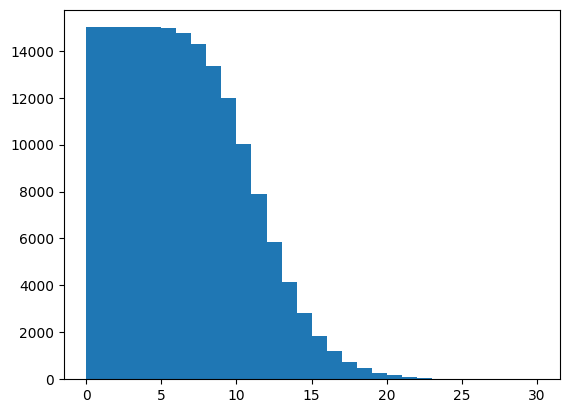

In [ ]:
#checking ditribution of line_number
import matplotlib.pyplot as plt
plt.hist(train_df["line_number"],bins=30,range=[0,30]);
plt.show()

In [ ]:
#upto how many lines cover 95 percent of data
np.percentile(train_df["line_number"],95)

np.float64(13.0)

In [ ]:
#using tensorlow for OHE in line_number
train_line_num_OHE=tf.one_hot(train_df["line_number"].to_numpy(),depth=15)
val_line_num_OHE=tf.one_hot(val_df["line_number"].to_numpy(),depth=15)
test_line_num_OHE=tf.one_hot(test_df["line_number"].to_numpy(),depth=15)

train_line_num_OHE[:10],train_line_num_OHE.shape




(<tf.Tensor: shape=(10, 15), dtype=float32, numpy=
 array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]],
       dtype=float32)>,
 TensorShape([180040, 15]))

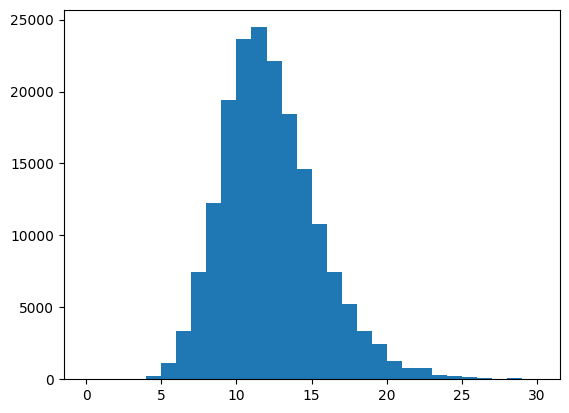

In [ ]:
#checking distribution of total_lines
plt.hist(train_df["total_lines"],bins=30,range=[0,30]);
plt.show()

In [ ]:
#how many lines cover 95 percent of lines
np.percentile(train_df["total_lines"],95)

np.float64(18.0)

In [ ]:
#OHE total lines
train_total_lines_OHE=tf.one_hot(train_df["total_lines"].to_numpy(),depth=20)
val_total_lines_OHE=tf.one_hot(val_df["total_lines"].to_numpy(),depth=20)
test_total_lines_OHE=tf.one_hot(test_df["total_lines"].to_numpy(),depth=20)

train_total_lines_OHE[:10],train_total_lines_OHE.shape

(<tf.Tensor: shape=(10, 20), dtype=float32, numpy=
 array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0

In [ ]:
#making embedding layer

##Building a Quadra model(Model 5)

In [ ]:
from tensorflow.keras import layers

# 1. Token Branch (Using custom token embeddings from Model 1)
token_inputs = layers.Input(shape=[], dtype=tf.string, name="token_inputs")
token_vectors = text_vectorizer(token_inputs)
token_embeddings = embedding(token_vectors)
x_token = layers.Conv1D(64, kernel_size=5, padding="same", activation="relu")(token_embeddings)
x_token = layers.GlobalAveragePooling1D()(x_token)
token_outputs = layers.Dense(64, activation="relu", name="token_output_layer")(x_token)
token_model = tf.keras.Model(inputs=token_inputs, outputs=token_outputs, name="token_model")

# 2. Character Branch (Using custom char embeddings from Model 3)
char_inputs = layers.Input(shape=(1,), dtype=tf.string, name="char_input_layer")
x_char = char_vectorizer(char_inputs)
x_char = char_embedding(x_char)
x_char = layers.Bidirectional(layers.LSTM(32), name="bidirectional_layer")(x_char)
char_model = tf.keras.Model(char_inputs, x_char, name="char_model")

# 3. Line Number Branch
line_num_inputs = layers.Input(shape=(15,), dtype=tf.float32, name="line_num_input_layer")
line_num_outputs = layers.Dense(64, activation="relu", name="line_num_output_layer")(line_num_inputs)
line_num_model = tf.keras.Model(line_num_inputs, line_num_outputs, name="line_num_model")

# 4. Total Lines Branch
total_lines_inputs = layers.Input(shape=(20,), dtype=tf.float32, name="total_lines_input_layer")
total_lines_outputs = layers.Dense(64, activation="relu", name="total_lines_output_layer")(total_lines_inputs)
total_lines_model = tf.keras.Model(total_lines_inputs, total_lines_outputs, name="total_lines_model")

# 5. Concatenate and Final Layers
concat_layer = layers.Concatenate(axis=1, name="concat_layer")([token_model.output,
                                                              char_model.output,
                                                              line_num_model.output,
                                                              total_lines_model.output])

# added dense to catch meanings
x = layers.Dropout(0.2)(concat_layer)
x = layers.Dense(512, activation="relu", name="dense_layer_1")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(256, activation="relu", name="dense_layer_2")(x)
x = layers.Dropout(0.2)(x)
output_layer = layers.Dense(num_classes, activation="softmax", name="output_layer")(x)

model_5 = tf.keras.Model(inputs=[token_model.input,
                                 char_model.input,
                                 line_num_model.input,
                                 total_lines_model.input],
                         outputs=output_layer,
                         name="model_5_quadra_model")

model_5.summary()

Model: "model_5_quadra_model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 token_inputs (InputLayer)   [(None,)]                    0         []                            
                                                                                                  
 text_vectorization_1 (Text  (None, 55)                   0         ['token_inputs[0][0]']        
 Vectorization)                                                                                   
                                                                                                  
 embedding_1 (Embedding)     (None, 55, 128)              8925696   ['text_vectorization_1[3][0]']
                                                                                                  
 char_input_layer (InputLay  [(None, 1)]                  0         []         

In [ ]:
#get a summary
model_5.summary()

Model: "model_5_quadra_model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 token_inputs (InputLayer)   [(None,)]                    0         []                            
                                                                                                  
 text_vectorization_1 (Text  (None, 55)                   0         ['token_inputs[0][0]']        
 Vectorization)                                                                                   
                                                                                                  
 embedding_1 (Embedding)     (None, 55, 128)              8925696   ['text_vectorization_1[3][0]']
                                                                                                  
 char_input_layer (InputLay  [(None, 1)]                  0         []         

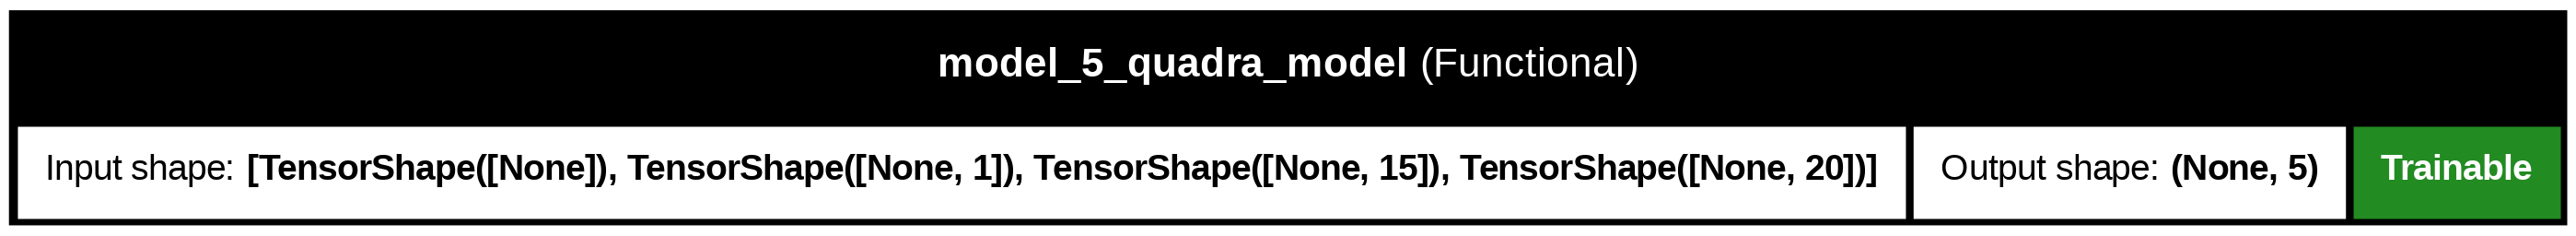

In [ ]:
#plot Quadra Model
import tensorflow as tf
from keras.utils import plot_model

plot_model(model_5,dpi=200,show_shapes=True,show_layer_names=True,show_dtype=False,to_file='Quadra_Model.png',show_layer_activations=True,show_trainable=True)

In [ ]:
#compile Quadra Model
model_5.compile(loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2 ),
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])

In [ ]:
import tensorflow as tf

# Prepare datasets using dictionary mapping to ensure names match the Input layers exactly
train_dataset = tf.data.Dataset.from_tensor_slices((
    {
        "token_inputs": train_lines,
        "char_input_layer": train_chars,
        "line_num_input_layer": train_line_num_OHE,
        "total_lines_input_layer": train_total_lines_OHE
    },
    train_labels_OHE
)).batch(32).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((
    {
        "token_inputs": val_lines,
        "char_input_layer": val_chars,
        "line_num_input_layer": val_line_num_OHE,
        "total_lines_input_layer": val_total_lines_OHE
    },
    val_labels_OHE
)).batch(32).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((
    {
        "token_inputs": test_lines,
        "char_input_layer": test_chars,
        "line_num_input_layer": test_line_num_OHE,
        "total_lines_input_layer": test_total_lines_OHE
    },
    test_labels_OHE
)).batch(32).prefetch(tf.data.AUTOTUNE)

print("Datasets created with explicit dictionary mapping.")

Datasets created with explicit dictionary mapping.


In [ ]:
#using import callbacks
from tensorflow.keras.callbacks import EarlyStopping

early_stopping=EarlyStopping(monitor="val_accuracy",
                             patience=4,
                             mode='max',
                             restore_best_weights=True)

In [ ]:
# Re-compiling WITHOUT run_eagerly for maximum speed
model_5.compile(loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"],
                run_eagerly=False)

# Re-fitting the model - this will now run much faster on the GPU
history_model_5 = model_5.fit(train_dataset,
                            epochs=10,
                            steps_per_epoch=int(0.1*len(train_dataset)),
                            validation_data=val_dataset,
                            callbacks=[tensorboard_callback, checkpoint, early_stopping])

Epoch 1/10


562/562 [==============================] - 215s 377ms/step - loss: 0.9365 - accuracy: 0.8268 - val_loss: 0.8967 - val_accuracy: 0.8506
Epoch 2/10
562/562 [==============================] - 186s 331ms/step - loss: 0.8512 - accuracy: 0.8872 - val_loss: 0.8634 - val_accuracy: 0.8660
Epoch 3/10
562/562 [==============================] - 171s 304ms/step - loss: 0.8374 - accuracy: 0.8930 - val_loss: 0.8598 - val_accuracy: 0.8592
Epoch 4/10
562/562 [==============================] - 185s 329ms/step - loss: 0.8319 - accuracy: 0.8991 - val_loss: 0.8589 - val_accuracy: 0.8719
Epoch 5/10
562/562 [==============================] - 177s 314ms/step - loss: 0.8281 - accuracy: 0.9031 - val_loss: 0.8627 - val_accuracy: 0.8688
Epoch 6/10
562/562 [==============================] - 169s 301ms/step - loss: 0.8294 - accuracy: 0.8972 - val_loss: 0.8479 - val_accuracy: 0.8760
Epoch 7/10
562/562 [==============================] - 210s 374ms/step - loss: 0.8201 - accuracy: 0.9032 - val_loss: 0.8502 - val_accura

In [ ]:
model_5_test_results = model_5.evaluate(test_dataset)
print(f"Model 5 Test Loss: {model_5_test_results[0]}")
print(f"Model 5 Test Accuracy: {model_5_test_results[1]*100:.2f}%")

# Make predictions to calculate F1-score and other metrics
model_5_test_probs = model_5.predict(test_dataset)
model_5_test_preds = tf.argmax(model_5_test_probs, axis=1)

# Using the helper function to get full results
model_5_final_metrics = calculate_results(y_true=test_labels, y_pred=model_5_test_preds)
display(model_5_final_metrics)

In [ ]:
#predictions model_5
model_5_preds=model_5.predict(test_dataset)
model_5_preds[:10],model_5_preds.shape


942/942 [==============================] - 76s 81ms/step


(array([[0.5694463 , 0.04030896, 0.04047165, 0.30646887, 0.04330423],
        [0.04649515, 0.03625032, 0.7935338 , 0.05042898, 0.07329171],
        [0.03821617, 0.03742976, 0.8032602 , 0.04233441, 0.07875936],
        [0.03444123, 0.03381812, 0.8205911 , 0.04031498, 0.07083454],
        [0.02820796, 0.02996003, 0.03142471, 0.03121536, 0.879192  ],
        [0.0291558 , 0.0259866 , 0.02501998, 0.03185135, 0.88798624],
        [0.02605669, 0.02510838, 0.02220936, 0.02795073, 0.8986748 ],
        [0.05874525, 0.799343  , 0.04239941, 0.04474454, 0.05476778],
        [0.03985905, 0.82850033, 0.03362432, 0.04238264, 0.05563368],
        [0.62499684, 0.04382632, 0.04794818, 0.2357465 , 0.04748213]],
       dtype=float32),
 (30135, 5))

In [ ]:
#pred_probs and labels
model_5_pred_probs=tf.squeeze(tf.round(model_5_preds))
model_5_pred_labels=tf.argmax(model_5_preds,axis=1).numpy()
model_5_pred_labels[:10]

array([0, 2, 2, 2, 4, 4, 4, 1, 1, 0])

In [ ]:
#result dictionary for model 5
model_5_results=calculate_results(y_true=test_labels,
                                  y_pred=model_5_pred_labels)
model_5_results

{'accuracy': 86.91886510701842,
 'precision': 0.8684953083828886,
 'recall': 0.8691886510701842,
 'f1': 0.8675072218772001}

In [ ]:
# dataframe for all model results including the updated MiniLM model
import pandas as pd
results = pd.DataFrame({"Naive_model": baseline_results,
                     "Custom_made_Feature_Ext_model": model_1_results,
                     "MiniLM_Feature_Ext_Model": model_2_results,
                     "Characterised_Token_Model": model_3_results,
                     "Multimodal_Model": model_4_results,
                     "Quadra_Model": model_5_results})

results

,Naive_model,Custom_made_Feature_Ext_model,MiniLM_Feature_Ext_Model,Characterised_Token_Model,Multimodal_Model,Quadra_Model
accuracy,72.183238,80.122781,76.382943,66.444334,80.640451,86.918865
precision,0.718647,0.797773,0.757591,0.678775,0.804886,0.868495
recall,0.721832,0.801228,0.763829,0.664443,0.806405,0.869189
f1,0.698925,0.797662,0.759376,0.666721,0.804016,0.867507


In [ ]:
import os
import pickle
from google.colab import files

# Create target directory
os.makedirs('saved_models', exist_ok=True)

# 1. Save Model 0 (Naive Bayes pipeline)
with open('saved_models/model_0.pkl', 'wb') as f:
    pickle.dump(model_0, f)
print("Saved Model 0 to saved_models/model_0.pkl")

# 2. Save Model 1 (Conv1D Token-level)
model_1.save('saved_models/model_1.keras')
print("Saved Model 1 to saved_models/model_1.keras")

# 3. Save Model 2 (USE Feature Extractor)
model_2.save('saved_models/model_2.keras')
print("Saved Model 2 to saved_models/model_2.keras")

# 4. Save Model 3 (Char-level Conv1D)
model_3.save('saved_models/model_3.keras')
print("Saved Model 3 to saved_models/model_3.keras")

# 5. Save Model 4 (Token + Char Hybrid)
model_4.save('saved_models/model_4.keras')
print("Saved Model 4 to saved_models/model_4.keras")

# 6. Save Model 5 (Quadra Model - Multimodal)
model_5.save('saved_models/model_5.keras')
print("Saved Model 5 to saved_models/model_5.keras")

# Zip the saved_models directory to download
!zip -r saved_models.zip saved_models/

# Download to your local machine
files.download('saved_models.zip')


Saved Model 0 to saved_models/model_0.pkl
Saved Model 1 to saved_models/model_1.keras
Saved Model 2 to saved_models/model_2.keras
Saved Model 3 to saved_models/model_3.keras
Saved Model 4 to saved_models/model_4.keras
Saved Model 5 to saved_models/model_5.keras
updating: saved_models/ (stored 0%)
updating: saved_models/model_0.pkl (deflated 47%)
updating: saved_models/model_1.keras (deflated 28%)
updating: saved_models/model_2.keras (deflated 12%)
updating: saved_models/model_5.keras (deflated 27%)
updating: saved_models/model_4.keras (deflated 28%)
updating: saved_models/model_3.keras (deflated 15%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install sentence-transformers
